# Part 1 Web Server Access Log Analysis

In [1]:
# 1.1 Web Server Access Log Analysis
access_log = open('accessLog.txt', 'r')
ufw_Log = open('ufwLog.txt', 'r')

access_lines = access_log.readlines()
ufw_lines = ufw_Log.readlines()

# How many total requests are in the log?
print("Number of entries in Access Log: " + str(len(access_lines)))
print("Number of entries in ufw Log: " + str(len(ufw_lines)))

# What do you notice about the IP addresses?
print("IP addresses in the log file consist of 172.28.246.84 which is a private IP address.")
print("There is also a couple other IP addresses that are public.")
# What are the most common HTTP status codes you see?
print("I am seeing a lot of 300 and 400 status codes. Specifically 302 and 404.")


Number of entries in Access Log: 1508
Number of entries in ufw Log: 4998
IP addresses in the log file consist of 172.28.246.84 which is a private IP address.
There is also a couple other IP addresses that are public.
I am seeing a lot of 300 and 400 status codes. Specifically 302 and 404.


In [2]:
# 1.2 Extract IP addresses
access_log = open('accessLog.txt', 'r')
ufw_Log = open('ufwLog.txt', 'r')

# What IP addresses made the most requests?
ip_counts = {}
for line in access_log:

    ip = line.split()[0]
    if ip in ip_counts:
        ip_counts[ip] += 1
    else:
        ip_counts[ip] = 1

sorted_ips = sorted(ip_counts.items(), key=lambda x: x[1], reverse=True)

print("Top IP addresses making the most requests:")
for ip, count in sorted_ips:
    print(f"{ip}: {count} requests")

# How many unique IP addresses accessed the server? 
unique_ips = len(ip_counts)
print(f"Number of unique IP addresses: {unique_ips}")

access_log.seek(0)  # Reset file pointer to the beginning
# Alternative method to count unique IPs with a set
unique_ips = set(line.split()[0] for line in access_log)
print(f"Number of unique IP addresses: {len(unique_ips)}")

# Do you see any patterns in the IP addresses?
print("Most IP addresses are from 172.28.246.84 as well as 152.42.219.58")


Top IP addresses making the most requests:
172.28.246.84: 860 requests
152.42.219.58: 374 requests
104.234.115.219: 46 requests
35.197.90.85: 16 requests
91.224.92.17: 14 requests
146.190.241.167: 13 requests
13.60.96.161: 11 requests
65.49.1.162: 6 requests
185.177.72.144: 6 requests
167.94.145.109: 5 requests
167.94.138.183: 5 requests
146.190.217.223: 4 requests
91.224.92.14: 4 requests
71.6.134.232: 4 requests
101.36.127.85: 4 requests
152.32.206.246: 4 requests
35.199.173.151: 4 requests
147.93.157.164: 4 requests
34.168.12.54: 4 requests
45.156.129.98: 4 requests
34.169.166.223: 4 requests
205.169.39.149: 4 requests
35.203.210.167: 3 requests
196.251.84.253: 3 requests
101.36.106.134: 3 requests
144.86.173.211: 3 requests
107.175.141.10: 3 requests
20.14.73.54: 2 requests
65.49.1.164: 2 requests
34.72.176.129: 2 requests
52.167.144.159: 2 requests
93.174.93.12: 2 requests
5.101.64.6: 2 requests
43.131.26.226: 2 requests
198.235.24.42: 2 requests
205.210.31.121: 2 requests
34.123.

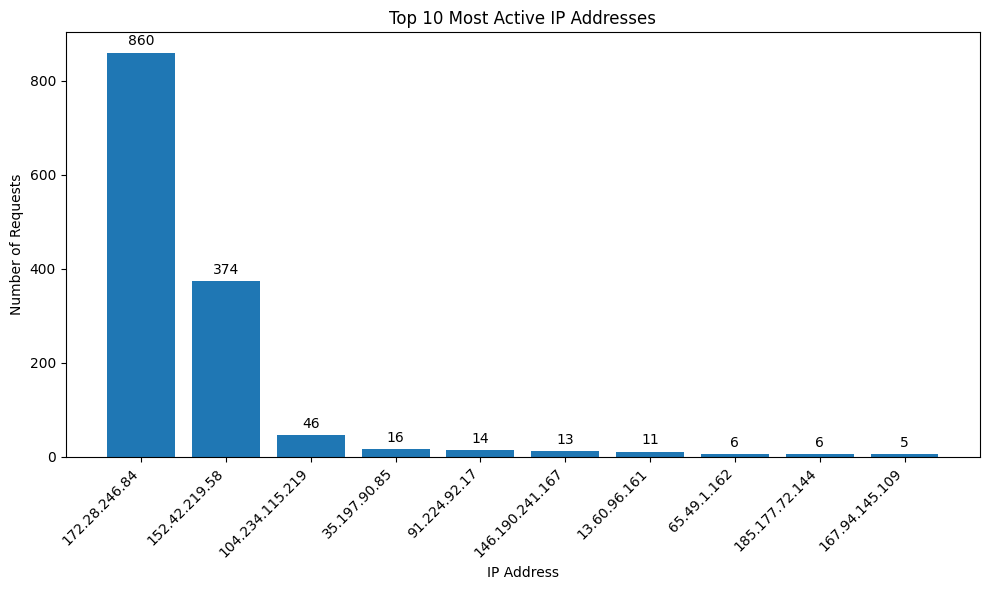

In [1]:
# 1.3 Simple Visualizaiton 
# ...existing code...
# 1.3 Simple Visualizaiton
from collections import Counter
import matplotlib.pyplot as plt


with open('accessLog.txt', 'r') as f:
    access_lines = [ln for ln in f if ln.strip()]

# extract IPs (first token of each non-empty line)
ips = [line.split()[0] for line in access_lines if line.strip()]

# count and get top N
counter = Counter(ips)
top_n = 10
top = counter.most_common(top_n)

if not top:
    print("No IP addresses found in the log.")
else:
    ips_top = [ip for ip, cnt in top]
    counts = [cnt for ip, cnt in top]

    plt.figure(figsize=(10, 6))
    plt.bar(ips_top, counts, color='C0')
    plt.title(f'Top {top_n} Most Active IP Addresses')
    plt.xlabel('IP Address')
    plt.ylabel('Number of Requests')
    plt.xticks(rotation=45, ha='right')
    # annotate bars with counts
    for i, v in enumerate(counts):
        plt.text(i, v + max(counts) * 0.01, str(v), ha='center', va='bottom')
    plt.tight_layout()
    plt.show()
# ...existing code...

# Part 2 Firewall Log Analysis


In [ ]:
# 2.1 Find Blocked Connections
blocked_connections = 0

ufw_Log = open('ufwLog.txt', 'r')
ufw_Log.seek(0)
# Count blocked connections
for line in ufw_Log:
    if "UFW BLOCK" in line:
        blocked_connections += 1

print(f"Total blocked connections: {blocked_connections}")


Total blocked connections: 4998


In [14]:
from collections import Counter

# 2.2 Extract Attacking IPs

# ictionary to store attacking IPs and their counts
attacking_ips = []

ufw_Log = open('ufwLog.txt', 'r')

for line in ufw_Log:
    for part in line.split():
        if part.startswith('SRC='):
            ip = part.replace('SRC=', '')
            attacking_ips.append(ip)

ip_counts = Counter(attacking_ips)

print("Top attacking IP addresses:")
for ip, count in ip_counts.most_common():
    print(f"{ip}: {count}")


Top attacking IP addresses:
172.24.50.77: 1098
0.0.0.0: 928
172.24.50.76: 770
172.24.50.75: 588
172.30.58.132: 519
172.30.58.137: 306
172.24.50.73: 273
172.30.58.133: 271
172.24.50.74: 150
146.186.152.22: 45
172.30.58.138: 38
172.28.246.84: 12


In [ ]:
# 2.3 Find Targeted Ports
from collections import Counter

# Refactored to identify targeted ports and their counts
targeted_ports = []

ufw_Log = open('ufwLog.txt', 'r')

for line in ufw_Log:
    for part in line.split():
        if part.startswith('DPT='):
            port = int(part.replace('DPT=', ''))
            targeted_ports.append(port)

port_counts = Counter(targeted_ports)

print("Top targeted ports:")
for port, count in port_counts.most_common():
    print(f"{port}: {count}")


Top targeted ports:
135: 2039
3389: 1974
161: 45
1299: 4
7199: 3
53: 2
21: 2
143: 1


### Can we figure out what system the attacker is trying to attack?

Yes the attacker is trying to attack a Windows device. The two most common ports are common Windows services such as RPC and RDP it sounds like the attacker is trying to remotly connect to the windows machine leveraging these two ports.

# Part 3 Basic Security Analysis

In [18]:
from collections import Counter
# 3.1 Compare the Data

access_log = open('accessLog.txt', 'r')
ufw_log = open('ufwLog.txt', 'r')

# Read non-empty lines
access_lines = [line for line in access_log if line.strip()]
ufw_lines = [line for line in ufw_log if line.strip()]

# Access log: IP list, counts and unique set
access_ips = [line.split()[0] for line in access_lines]
access_counts = Counter(access_ips)
access_unique = set(access_ips)

# UFW log: extract SRC= IPs, counts and unique set
ufw_srcs = []
for line in ufw_lines:
    for part in line.split():
        if part.startswith('SRC='):
            ufw_srcs.append(part.replace('SRC=', ''))
ufw_counts = Counter(ufw_srcs)
ufw_unique = set(ufw_srcs)

# Intersection
common_ips = access_unique.intersection(ufw_unique)

# Print summary
print(f"Unique IPs in access log: {len(access_unique)}")
print(f"Unique IPs in ufw log: {len(ufw_unique)}")
print(f"IPs appearing in both logs: {len(common_ips)}")

print('\nCommon IPs with (access_requests, ufw_blocks):')
for ip in sorted(common_ips):
    print(f"{ip}: {access_counts.get(ip)} requests, {ufw_counts.get(ip)} blocks")

# Close files
access_log.close()
ufw_log.close()


Unique IPs in access log: 100
Unique IPs in ufw log: 12
IPs appearing in both logs: 1

Common IPs with (access_requests, ufw_blocks):
172.28.246.84: 860 requests, 12 blocks
172.28.246.84: 860 requests, 12 blocks


### What does this mean?

This means that 172.28.246.84 is an attacker that is being blocked by our firewall but is also still connection to our web server.

## 3.2 Basic Threat Assessment

1. If you saw port 3389 being targeted, what would that tell you?

That  would likely tell me that someone is trying to connect to a Windows machine via Remote Desktop Protocol (RDP). If they are doing it a lot with no success or making a bunch of requests I would assume that they are trying to brute force entry into a RDP machine.

2. If the same IP hits many different ports, what might that indicate?

If the same IP address is hitting a bunch of different ports my assumption is that they are doing a port scan and trying to find out which ports are availible for potential attack vectors.

3. If web server logs show normal traffic while firewall blocks attacks, what does that suggest?

It likely means that the attacker found a way to bipass the firewall in some way.



# Part 4 Simple Dashboard

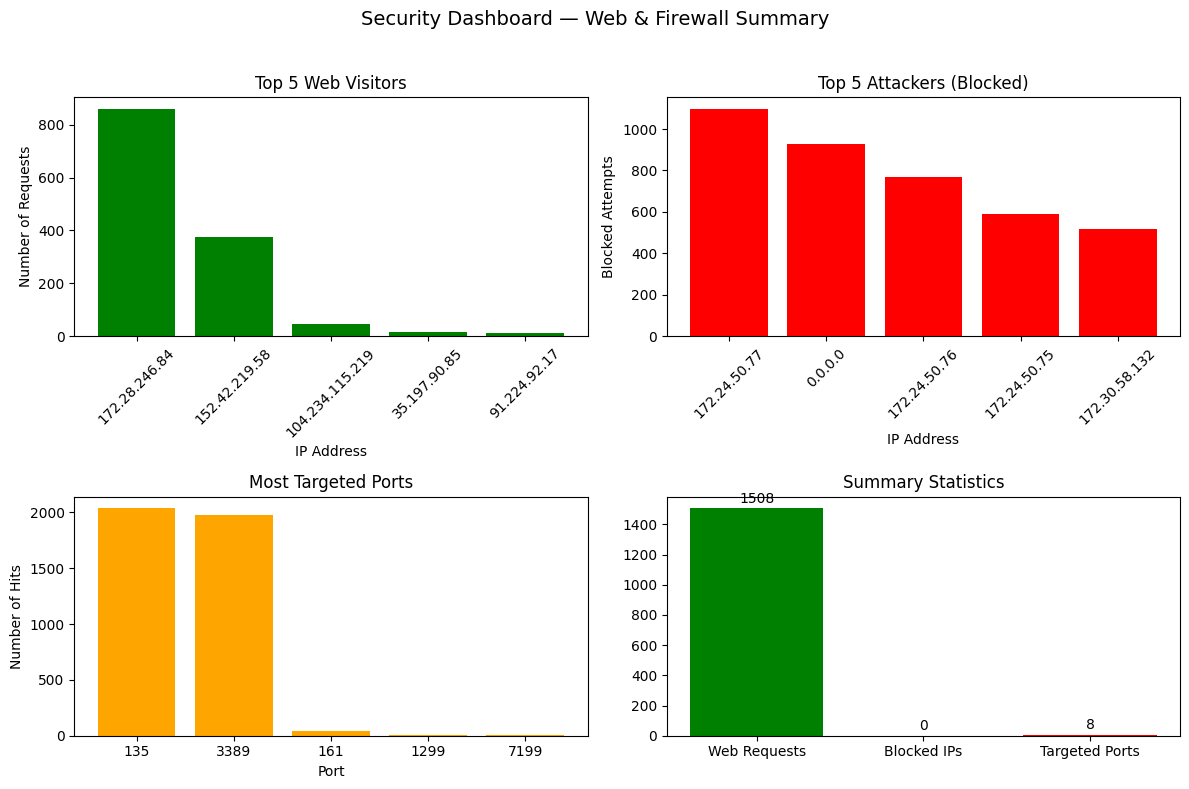

In [24]:
# 4.1 Create a Basic Security Dashboard
from collections import Counter
import matplotlib.pyplot as plt

# read files the same way as earlier cells
access_log = open('accessLog.txt', 'r')
ufw_Log = open('ufwLog.txt', 'r')

access_lines = access_log.readlines()
access_lines = [ln for ln in access_lines if ln.strip()]

ufw_lines = ufw_Log.readlines()
ufw_lines = [ln for ln in ufw_lines if ln.strip()]

# prepare web visitor data (top 5)
access_ips = [line.split()[0] for line in access_lines]
access_counts = Counter(access_ips)
top_web = access_counts.most_common(5)
web_ips = [ip for ip, cnt in top_web]
web_counts = [cnt for ip, cnt in top_web]

# prepare attacker data and targeted ports (from ufw lines)
attacking_ips = []
targeted_ports = []
blocked_count = 0
for line in ufw_lines:
    if "[UFW BLOCK]" in line:
        blocked_count += 1
    for part in line.split():
        if part.startswith('SRC='):
            attacking_ips.append(part.replace('SRC=', ''))
        if part.startswith('DPT='):
            try:
                targeted_ports.append(int(part.replace('DPT=', '')))
            except ValueError:
                pass

attack_counts = Counter(attacking_ips).most_common(5)
attack_ips = [ip for ip, cnt in attack_counts]
attack_counts_vals = [cnt for ip, cnt in attack_counts]

port_counts = Counter(targeted_ports).most_common(5)
ports = [p for p, cnt in port_counts]
ports_counts = [cnt for p, cnt in port_counts]

# summary stats
summary_labels = ["Web Requests", "Blocked IPs", "Targeted Ports"]
summary_values = [len(access_lines), blocked_count, len(set(targeted_ports))]

# create 2x2 dashboard
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
fig.suptitle("Security Dashboard — Web & Firewall Summary", fontsize=14)

# Chart 1 - Top Web Visitors
ax = axes[0, 0]
if web_ips:
    ax.bar(web_ips, web_counts, color='green')
    ax.set_xlabel("IP Address")
    ax.set_ylabel("Number of Requests")
ax.set_title("Top 5 Web Visitors")
ax.tick_params(axis='x', rotation=45)

# Chart 2 - Top Attackers (Blocked)
ax = axes[0, 1]
if attack_ips:
    ax.bar(attack_ips, attack_counts_vals, color='red')
    ax.set_xlabel("IP Address")
    ax.set_ylabel("Blocked Attempts")
ax.set_title("Top 5 Attackers (Blocked)")
ax.tick_params(axis='x', rotation=45)

# Chart 3 - Most Targeted Ports
ax = axes[1, 0]
if ports:
    ax.bar([str(p) for p in ports], ports_counts, color='orange')
    ax.set_xlabel("Port")
    ax.set_ylabel("Number of Hits")
ax.set_title("Most Targeted Ports")

# Chart 4 - Summary Statistics
ax = axes[1, 1]
ax.bar(summary_labels, summary_values, color=['green', 'orange', 'red'])
for i, v in enumerate(summary_values):
    ax.text(i, v + max(summary_values) * 0.01, str(v), ha='center', va='bottom')
ax.set_title("Summary Statistics")

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

# close files
access_log.close()
ufw_Log.close()
